Numerical differentiation 

This is the code for the discretization of the differentiation problem by a matrix A
$$y(t) = Kx(t) = \int_0^t x(s) \; \mathrm ds$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# True solution x(s) and data y(s)
y = lambda s: s * np.exp(-s)
x = lambda s: np.exp(-s) * (1 - s)

# Grid initialization
N = 256
h = 1 / N
s = np.linspace(0, 1 - h, N)

# Evaluate x on grid
xvec = x(s)

# Matrix A: left-point quadrature rule (lower triangular matrix)
A = np.tril(np.ones((N, N))) * h

# Compute yvec = A * xvec
yvec = A @ xvec


Noise level: 0.03532800894431844
Relative error: 7.4017507438713634


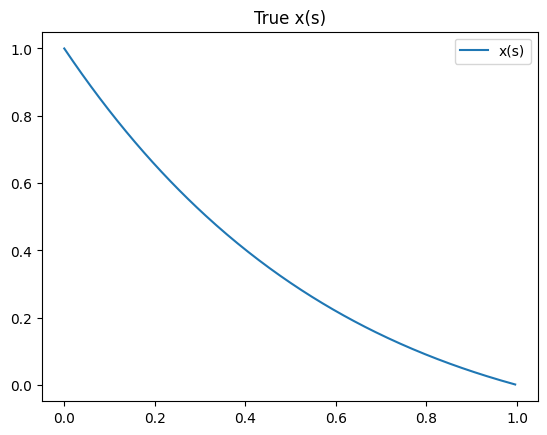

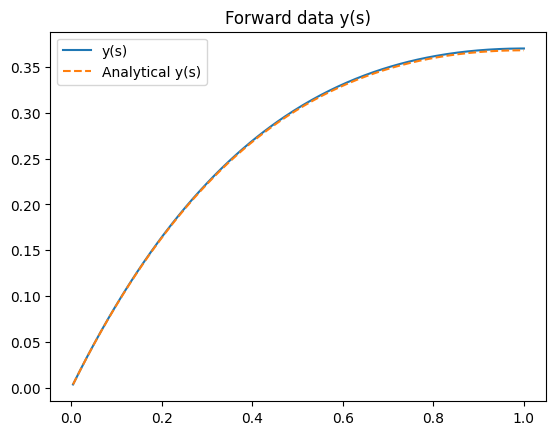

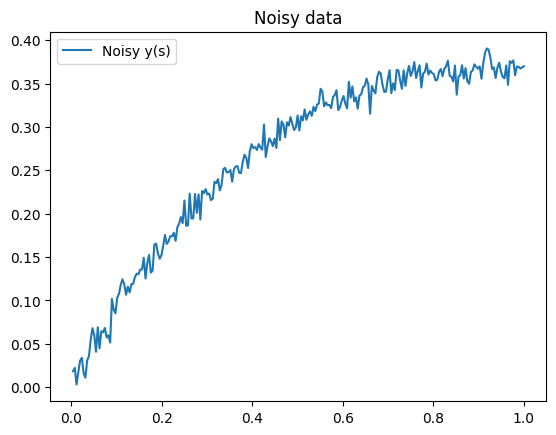

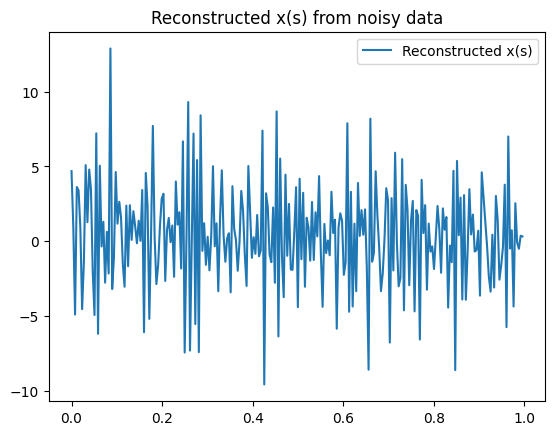

In [2]:
#Simple experiment with numerical differentiation
# Add noise
noise = 0.01 * np.random.randn(N)
yvecnoise = yvec + noise
noiselevel = np.linalg.norm(noise) / np.linalg.norm(yvec)
print("Noise level:", noiselevel)

# Naive inverse solution (commented out in original)
xvecrecon = np.linalg.solve(A, yvecnoise)

# Relative error (if inverse is computed)
relerror = np.linalg.norm(xvec - xvecrecon) / np.linalg.norm(xvec)
print("Relative error:", relerror)

# Optional plots
plt.figure()
plt.plot(s, xvec, label='x(s)')
plt.legend()
plt.title('True x(s)')
plt.show()

plt.figure()
plt.plot(s + h, yvec, label='y(s)')
plt.plot(s + h, y(s + h), '--', label='Analytical y(s)')
plt.legend()
plt.title('Forward data y(s)')
plt.show()

plt.figure()
plt.plot(s + h, yvecnoise, label='Noisy y(s)')
plt.legend()
plt.title('Noisy data')
plt.show()

plt.figure()
plt.plot(s, xvecrecon, label='Reconstructed x(s)')
plt.legend()
plt.title('Reconstructed x(s) from noisy data')
plt.show()


Abel problem

Below is a code for approximating the forward Abel problem by a matrix A
$$ y(t) = Kx(t) =\int_0^t \frac{x(s)}{\sqrt{t-s}}\;\mathrm ds

In [3]:
import numpy as np

# Abel integral operator approximation
# Problem: Approximate Kx(t) = ∫₀ᵗ x(s)/√(t-s) ds
# using numerical quadrature on offset s and t grids to avoid the singularity.
# Translated from MATLAB by Kim Knudsen (2024)

# Set number of discretization points
N = 256
h = 1 / N  # grid spacing

# Create s and t vectors with offset to avoid singularity at s = t
svec = np.linspace(h/2, 1 - h/2, N)  # midpoints of intervals
tvec = svec + h/2                    # shifted t values
tvec = tvec.reshape(-1, 1)           # make tvec a column vector

# Create matrices for pairwise differences
sMatrix = np.tile(svec, (N, 1))      # each row is svec
tMatrix = np.tile(tvec, (1, N))      # each column is tvec

# Initialize matrix A
A = np.zeros((N, N))

# Compute entries of A where s < t
index = sMatrix < tMatrix
A[index] = h / np.sqrt(np.abs(tMatrix[index] - sMatrix[index]))

# A now approximates the Abel integral operator
A.shape

(256, 256)

Heat problem

This code approximtaes the forward heat problem by a matrix A. We use FFT and need to take care of periodic extensions (the problem is formulated with zero bdr. conditions, therefore the zero padding)

257


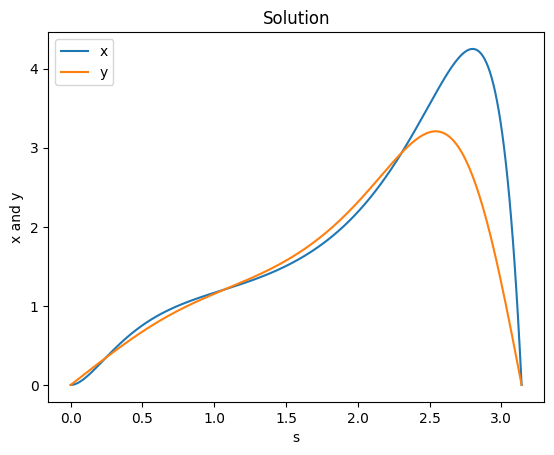

Relative error: 0.8348345347659529


In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
m = 11
L = np.pi  # Length of the interval
N = 2**8   # Number of spatial points
ds = L / N  # Spatial step size
s = np.linspace(0, L, N + 1)  # Spatial grid
print(len(s))

# Terminal time
T = 0.05

# Initial condition
u0 = s * np.sin(s) * np.exp((s - np.pi / 2)**2)  # Example initial condition
# u0 = np.sin(m * s)
x0 = u0

# Heat operator function
def HF(x0, T):
    N = len(x0) - 1
    k = np.fft.fftshift(np.arange(-N, N))  # Wave numbers

    # Odd extension to enforce sine series
    x = x0[1:-1]
    x_ext = np.concatenate(([0], x, [0], -x[::-1]))

    # FFT and time evolution
    x_hat = np.fft.fft(x_ext)
    x_hatT = x_hat * np.exp(-k**2 * T)
    xend = np.fft.ifft(x_hatT)

    return np.real(xend[:N+1])

# Compute terminal distribution
y = HF(x0, T)

# Plot
plt.plot(s, x0, label='x')
plt.plot(s, y, label='y')
plt.xlabel('s')
plt.ylabel('x and y')
plt.legend()
plt.title('Solution')
plt.show()

# Error norm - estimate the error against the true solution
error = np.linalg.norm(np.exp(-m**2 * T) * x0 - y) / np.linalg.norm(x0)
print("Relative error:", error)

# Compute matrix A
A = np.zeros((N + 1, N + 1))
Id = np.eye(N + 1)

for kk in range(N):
    A[:, kk] = HF(Id[:, kk], T)

# A is now the matrix representation of the heat operator


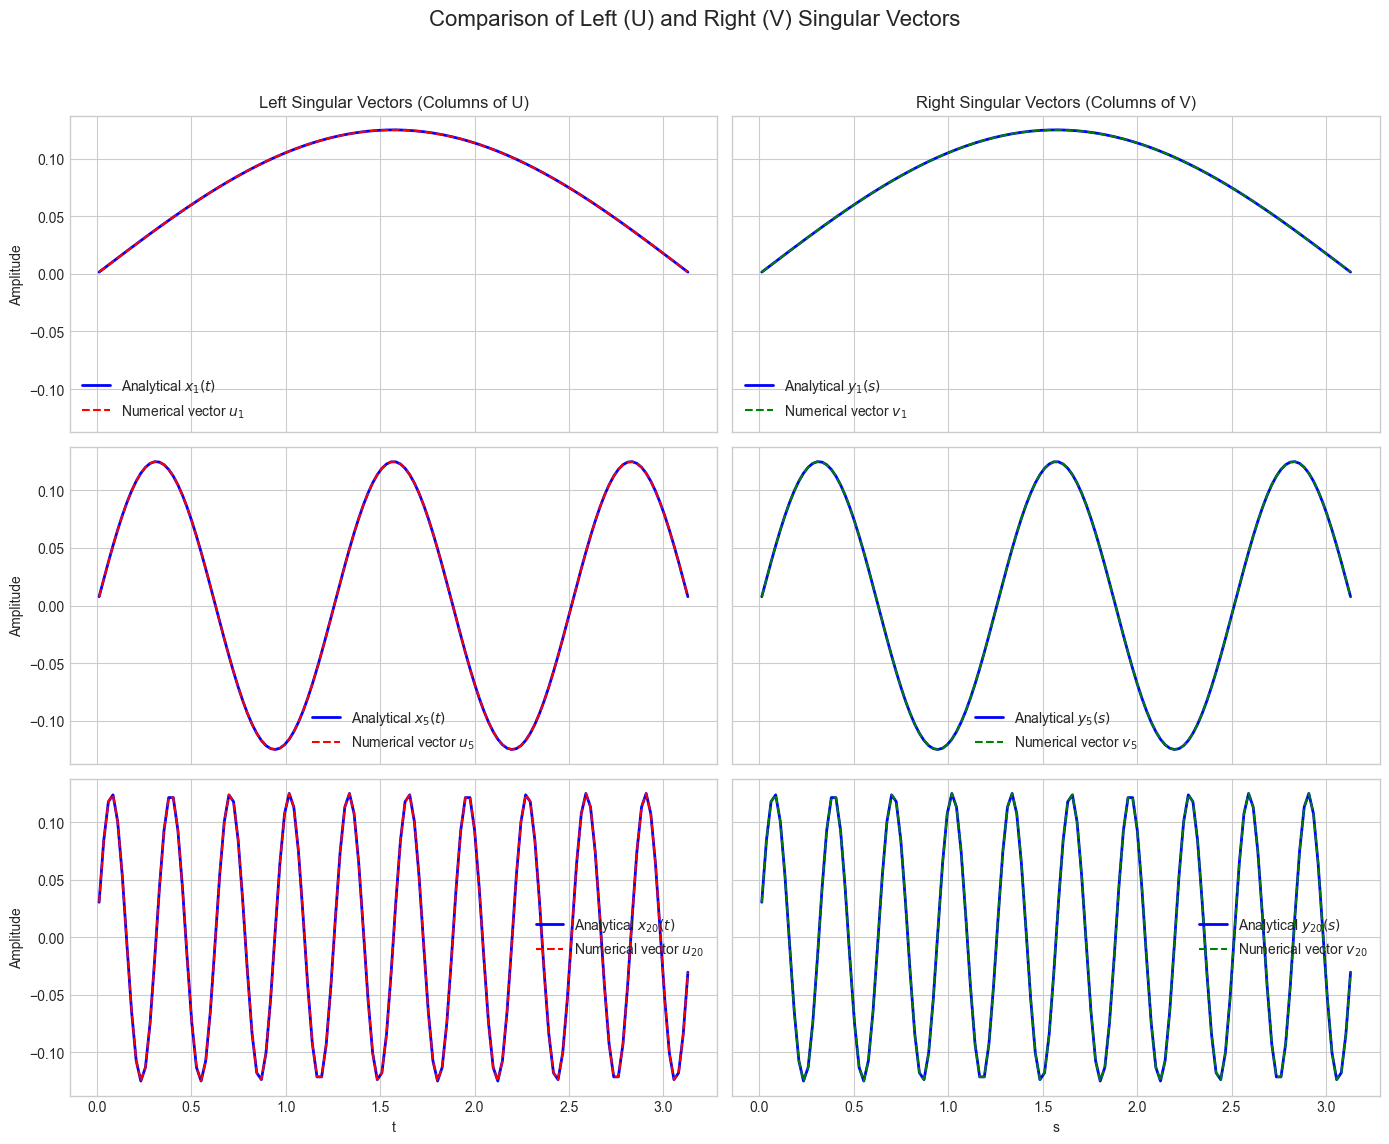

Are the absolute values of U and V element-wise close? False
First 5 diagonal elements of U.T @ V: [1. 1. 1. 1. 1.]
Are all diagonal elements of U.T @ V close to +/- 1? False


In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid')

# --- Step 1: Define Parameters and Grid ---
T = 0.03
n = 128
h = np.pi / n

# s corresponds to columns (j), t corresponds to rows (i)
# The grids are identical for this problem
s_grid = (np.arange(n) + 0.5) * h
t_grid = (np.arange(n) + 0.5) * h

# --- Step 2: Construct the Kernel Matrix A ---

def kernel(t, s, T, n_sum):
    m = np.arange(1, n_sum + 1).reshape(-1, 1, 1)
    t_b = t.reshape(1, -1, 1)
    s_b = s.reshape(1, 1, -1)
    terms = np.exp(-T * m**2) * np.sin(m * t_b) * np.sin(m * s_b)
    k_val = (2 / np.pi) * np.sum(terms, axis=0)
    return k_val

A = kernel(t_grid, s_grid, T, n_sum=n) * h

# --- Step 3: Compute SVD of A ---
U, s_A, Vh = np.linalg.svd(A)
V = Vh.T # Vh is V transpose, so we take the transpose to get V

# --- Step 4: Analytical Singular Functions ---
def singular_function(grid, j_val):
    return np.sqrt(2 / np.pi) * np.sin(j_val * grid)

# --- Step 5: Plotting Comparison of U and V ---

# Choose a few indices to compare
indices_to_plot = [0, 4, 19] # Corresponds to j=1, 5, 20

fig, axes = plt.subplots(len(indices_to_plot), 2, figsize=(14, 12), sharex=True, sharey=True)
fig.suptitle(f'Comparison of Left (U) and Right (V) Singular Vectors', fontsize=16)

for i, idx in enumerate(indices_to_plot):
    j_val = idx + 1 # Convert 0-based index to 1-based j

    # --- Left Column: Left Singular Vectors (U) ---
    ax_left = axes[i, 0]
    u_numerical = U[:, idx]
    x_analytical_discrete = singular_function(t_grid, j_val)
    x_analytical_normalized = x_analytical_discrete * np.sqrt(h)

    # Correct sign for plotting
    if np.dot(u_numerical, x_analytical_normalized) < 0:
        u_numerical *= -1
    
    ax_left.plot(t_grid, x_analytical_normalized, 'b-', lw=2, label=f'Analytical $x_{{{j_val}}}(t)$')
    ax_left.plot(t_grid, u_numerical, 'r--', label=f'Numerical vector $u_{{{j_val}}}$')
    ax_left.legend()
    ax_left.set_ylabel('Amplitude')
    if i == 0:
        ax_left.set_title(f'Left Singular Vectors (Columns of U)')


    # --- Right Column: Right Singular Vectors (V) ---
    ax_right = axes[i, 1]
    v_numerical = V[:, idx]
    y_analytical_discrete = singular_function(s_grid, j_val)
    y_analytical_normalized = y_analytical_discrete * np.sqrt(h)

    # Correct sign for plotting
    if np.dot(v_numerical, y_analytical_normalized) < 0:
        v_numerical *= -1

    ax_right.plot(s_grid, y_analytical_normalized, 'b-', lw=2, label=f'Analytical $y_{{{j_val}}}(s)$')
    ax_right.plot(s_grid, v_numerical, 'g--', label=f'Numerical vector $v_{{{j_val}}}$')
    ax_right.legend()
    if i == 0:
        ax_right.set_title(f'Right Singular Vectors (Columns of V)')


axes[-1, 0].set_xlabel('t')
axes[-1, 1].set_xlabel('s')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

# Verify numerically that U and V are the same (up to sign)
# We can check if |U| = |V| element-wise.
print(f"Are the absolute values of U and V element-wise close? {np.allclose(np.abs(U), np.abs(V))}")
# We can also check if U.T @ V is close to a signed identity matrix.
# The diagonal elements should be +/- 1.
diag_UTV = np.diag(U.T @ V)
print(f"First 5 diagonal elements of U.T @ V: {diag_UTV[:5]}")
print(f"Are all diagonal elements of U.T @ V close to +/- 1? {np.allclose(np.abs(diag_UTV), np.ones(n))}")

Blurring problem

This is the Philips test problem that approximates by a matrix A a blurring

In [6]:
import numpy as np
from scipy.linalg import toeplitz

# Number of points on interval (-6,6); n/4 must be a positive integer
n = 2**8

# Setup
h = 12 / n
n4 = n // 4
r1 = np.zeros(n)

# Cosine values for the formula
c = np.cos(np.arange(-1, n4 + 1) * 4 * np.pi / n)

# Fill in the first n/4 entries
r1[:n4] = h + 9 / (h * np.pi**2) * (2 * c[1:n4 + 1] - c[:n4] - c[2:n4 + 2])

# Middle entry
r1[n4] = h / 2 + 9 / (h * np.pi**2) * (np.cos(4 * np.pi / n) - 1)

# Construct Toeplitz matrix
A = toeplitz(r1)
